In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('the-office_lines.csv')
df.head()

,Unnamed: 0,Character,Line,Season,Episode_Number
0,0,Michael,All right Jim. Your quarterlies look very goo...,1,1
1,1,Jim,"Oh, I told you. I couldn’t close it. So…",1,1
2,2,Michael,So you’ve come to the master for guidance? Is...,1,1
3,3,Jim,"Actually, you called me in here, but yeah.",1,1
4,4,Michael,"All right. Well, let me show you how it’s don...",1,1


In [3]:
df.groupby('Season')['Episode_Number'].nunique()

Season
1     6
2    22
3    23
4    13
5    25
6    24
7    24
8    24
9    23
Name: Episode_Number, dtype: int64

In [5]:
df.groupby('Season').nunique()

,Unnamed: 0,Character,Line,Episode_Number
Season,,,,
1,1986,32,1859,6
2,7449,130,6850,22
3,7441,118,6832,23
4,5003,109,4671,13
5,7780,141,7198,25
6,7583,149,7064,24
7,7376,168,6921,24
8,7034,135,6501,24
9,7069,190,6502,23


In [7]:
df.groupby('Season')['Episode_Number'].nunique().sum()

184

In [10]:
twss = df[df['Line'].str.contains("That's what she said",case=False,regex=False)]

In [12]:
print(len(twss.index))

0


In [13]:
thats_what_she_said = df[df['Line'].str.contains("what she said", case=False, regex=False)]
thats_what_she_said

,Unnamed: 0,Character,Line,Season,Episode_Number
2529,2694,Michael,That’s what she said. Pam?,2,2
2575,2740,Jim,Does that include ‘That’s What She Said’?,2,2
2578,2743,Michael,THAT’S WHAT SHE SAID!,2,2
5294,5634,Michael,"A, that’s what she said, and B, I wanted it t...",2,10
6287,6675,Dwight,That’s what she said.,2,12
6318,6707,Michael,"Uh, that’s what she said. See, haven’t lost ...",2,12
7599,8083,Michael,That’s what she said!,2,17
8820,9394,Michael,That’s what she said. [Jim mouths these words...,2,21
9569,10187,Michael,I am glad that today spurred social change. ...,3,1
10841,11527,Stanley,That’s what she said. [Stanley and Michael bo...,3,5


In [14]:
thats_what_she_said.count()

Unnamed: 0        34
Character         34
Line              34
Season            34
Episode_Number    34
dtype: int64

In [15]:
print(len(thats_what_she_said.index))

34


In [16]:
chars = thats_what_she_said.loc[:, ['Character', 'Line']].groupby(['Character']).count()
chars

,Line
Character,
Creed,1
David,1
Dwight,3
Everyone,1
Holly,1
Jan,1
Jim,2
Michael,22
Pam,1


<AxesSubplot:ylabel='Line'>

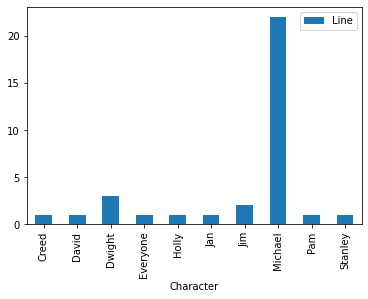

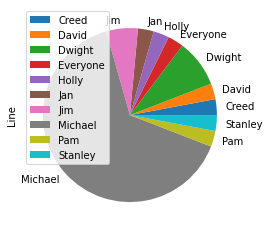

In [17]:
chars.plot.bar(y='Line')
chars.plot.pie(y='Line')

In [18]:
seasons = thats_what_she_said.loc[:, ['Season', 'Line']].groupby(['Season']).count()
seasons

,Line
Season,
2,8
3,8
4,6
5,5
6,1
7,4
9,2


<AxesSubplot:ylabel='Line'>

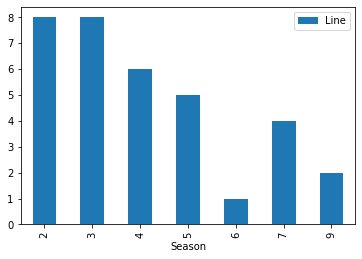

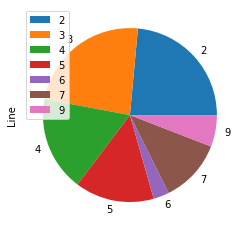

In [19]:
seasons.plot.bar(y='Line')
seasons.plot.pie(y='Line')

In [21]:
seasons.groupby('Season')['Line'].sum()

Season
2    8
3    8
4    6
5    5
6    1
7    4
9    2
Name: Line, dtype: int64

In [22]:
thats_what_she_said['Season_Episode'] = thats_what_she_said['Season'].astype(str) + thats_what_she_said['Episode_Number'].astype(str)

<ipython-input-22-e67240ee8177>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  thats_what_she_said['Season_Episode'] = thats_what_she_said['Season'].astype(str) + thats_what_she_said['Episode_Number'].astype(str)


In [23]:
thats_what_she_said

,Unnamed: 0,Character,Line,Season,Episode_Number,Season_Episode
2529,2694,Michael,That’s what she said. Pam?,2,2,22
2575,2740,Jim,Does that include ‘That’s What She Said’?,2,2,22
2578,2743,Michael,THAT’S WHAT SHE SAID!,2,2,22
5294,5634,Michael,"A, that’s what she said, and B, I wanted it t...",2,10,210
6287,6675,Dwight,That’s what she said.,2,12,212
6318,6707,Michael,"Uh, that’s what she said. See, haven’t lost ...",2,12,212
7599,8083,Michael,That’s what she said!,2,17,217
8820,9394,Michael,That’s what she said. [Jim mouths these words...,2,21,221
9569,10187,Michael,I am glad that today spurred social change. ...,3,1,31
10841,11527,Stanley,That’s what she said. [Stanley and Michael bo...,3,5,35


In [24]:
eps = thats_what_she_said.loc[:, ['Season_Episode', 'Line']].groupby(['Season_Episode']).count()
eps

,Line
Season_Episode,
210,1
212,2
217,1
22,3
221,1
31,1
310,1
312,1
317,2


In [25]:
eps.count()

Line    29
dtype: int64

In [26]:
print(len(eps.index))

29
